**PROJECT 34:**

Jaakko Hietikko

Jani-Matti Laasonen Y68417011

Urho Väyrynen 2214968

**1. Data Exploration and Preprocessing:** Explore the distribution of tweets by sentiment, Age of User,
Country, and Time of Tweet. Visualize the data using appropriate charts such as bar charts, histograms,
and heatmaps. 

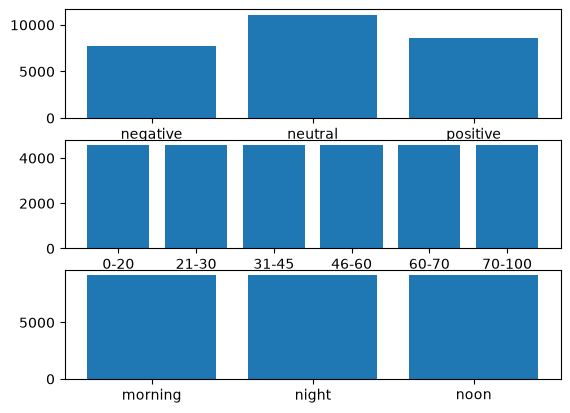

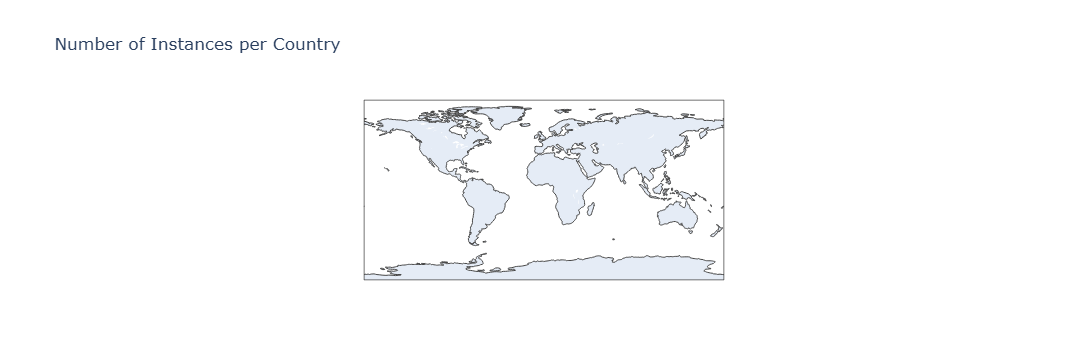

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

data = pd.read_csv("train.csv", encoding="latin1")
data_sentiment = data["sentiment"]
data_age_of_user = data["Age of User"]
data_country = data["Country"]
data_time_of_tweet = data["Time of Tweet"]
data_density = data["Density (P/Km²)"]
y = data_sentiment.value_counts().sort_index()
z = data_age_of_user.value_counts().sort_index()
x = data_country.value_counts().sort_index()
i = data_time_of_tweet.value_counts().sort_index()
j = data_density.value_counts().sort_index()

fig, ax = plt.subplots(3)

ax[0].bar(y.index, y.values)
ax[1].bar(z.index, z.values)
ax[2].bar(i.index, i.values)

plt.show()

country_df = x.rename_axis("Country").reset_index(name="Count")

fig = px.choropleth(
    country_df,
    locations="Country",
    locationmode="country names",
    color="Count",
    hover_name="Country",
    color_continuous_scale="Viridis",
    title="Number of Instances per Country"
)

fig.show()

**2. Exploratory Analysis of Demographics:** Analyze the correlation between demographic
information (e.g., Age of User, Country) and the sentiment of the tweets. Identify if certain age groups
or countries tend to express more positive, negative, or neutral sentiments. Also. analyze how density
affects sentiment patterns.

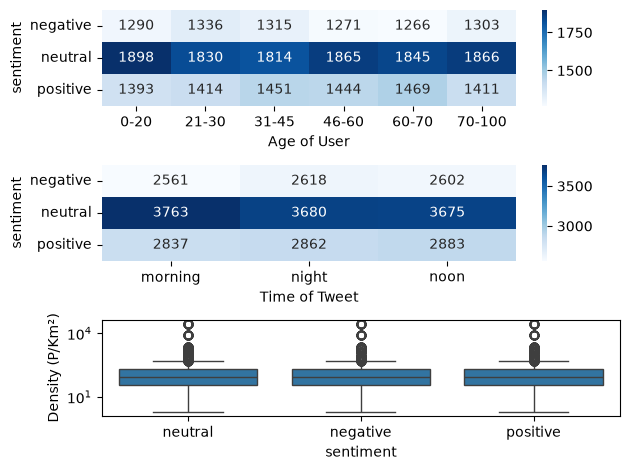

Spearman correlation between sentiment and time of tweet: 0.000
P-value: 0.9477
Spearman correlation between sentiment and age of user: 0.006
P-value: 0.3156
Spearman correlation between sentiment and density: 0.003
P-value: 0.5747


In [4]:
import numpy as np
import seaborn as sns
from scipy.stats import spearmanr

cross_table = pd.crosstab(data_sentiment, data_age_of_user)
cross_table2 = pd.crosstab(data_sentiment, data_time_of_tweet)
cross_table3 = pd.crosstab(data_sentiment, data_density)

fig, ax = plt.subplots(3)

sns.heatmap(cross_table, annot=True, fmt="d", cmap="Blues", ax=ax[0])
sns.heatmap(cross_table2, annot=True, fmt="d", cmap="Blues", ax=ax[1])
sns.boxplot(data=data, x="sentiment",y="Density (P/Km²)", ax=ax[2])
ax[2].set_yscale("log")

plt.tight_layout()
plt.show()

def correlation(data1, data2, subject1, subject2):
    rho, p_value = spearmanr(
        data1,
        data2,
        nan_policy="omit"
    )
    
    print(f"Spearman correlation between {subject1} and {subject2}: {rho:.3f}")
    print(f"P-value: {p_value:.4f}")

correlation(data["sentiment"], data["Time of Tweet"], "sentiment", "time of tweet")
correlation(data["sentiment"], data["Age of User"], "sentiment", "age of user")
correlation(data["sentiment"], data["Density (P/Km²)"], "sentiment", "density")

**3. Time of Tweet and Sentiment Trends:** Investigate how the time of tweet (morning, noon, night)
correlates with sentiment. Do people tend to tweet more positively or negatively at certain times of the
day? Visualize sentiment trends over time to identify any patterns (e.g., higher negativity during late
hours or weekends)

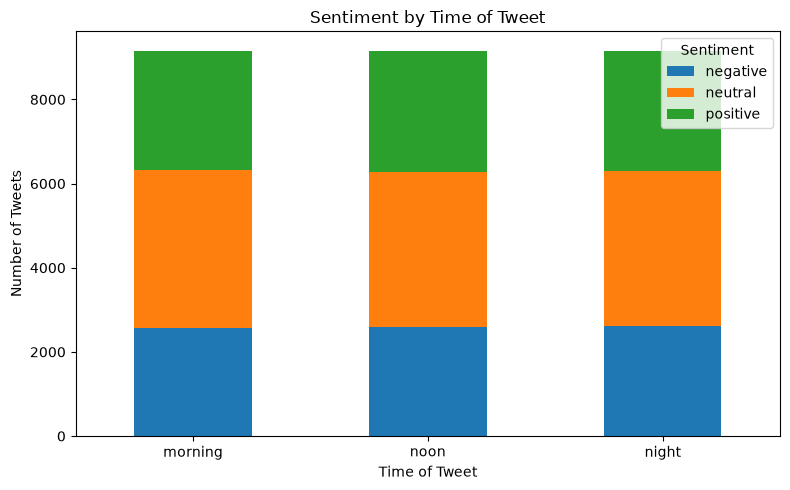

In [5]:
time_sentiment = pd.crosstab(data['Time of Tweet'], data['sentiment']).reindex(['morning', 'noon', 'night'], fill_value=0)

time_sentiment.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Sentiment by Time of Tweet')
plt.xlabel('Time of Tweet')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

**4. Topic Modeling with LDA on Tweets:** The main aim of this task is to use LDA (Latent Dirichlet
Allocation) to discover hidden topics within the tweet dataset and analyze how these topics correlate
with different sentiment classes (positive, neutral, negative). Apply LDA to the text or selected_text
field to identify the most common topics discussed in the tweets. After extracting the topics, categorize
tweets based on the most likely topic and analyze the distribution of sentiment across different topics.
Visualize the topics using word clouds or bar charts to interpret the most frequent words associated
with each topic. 

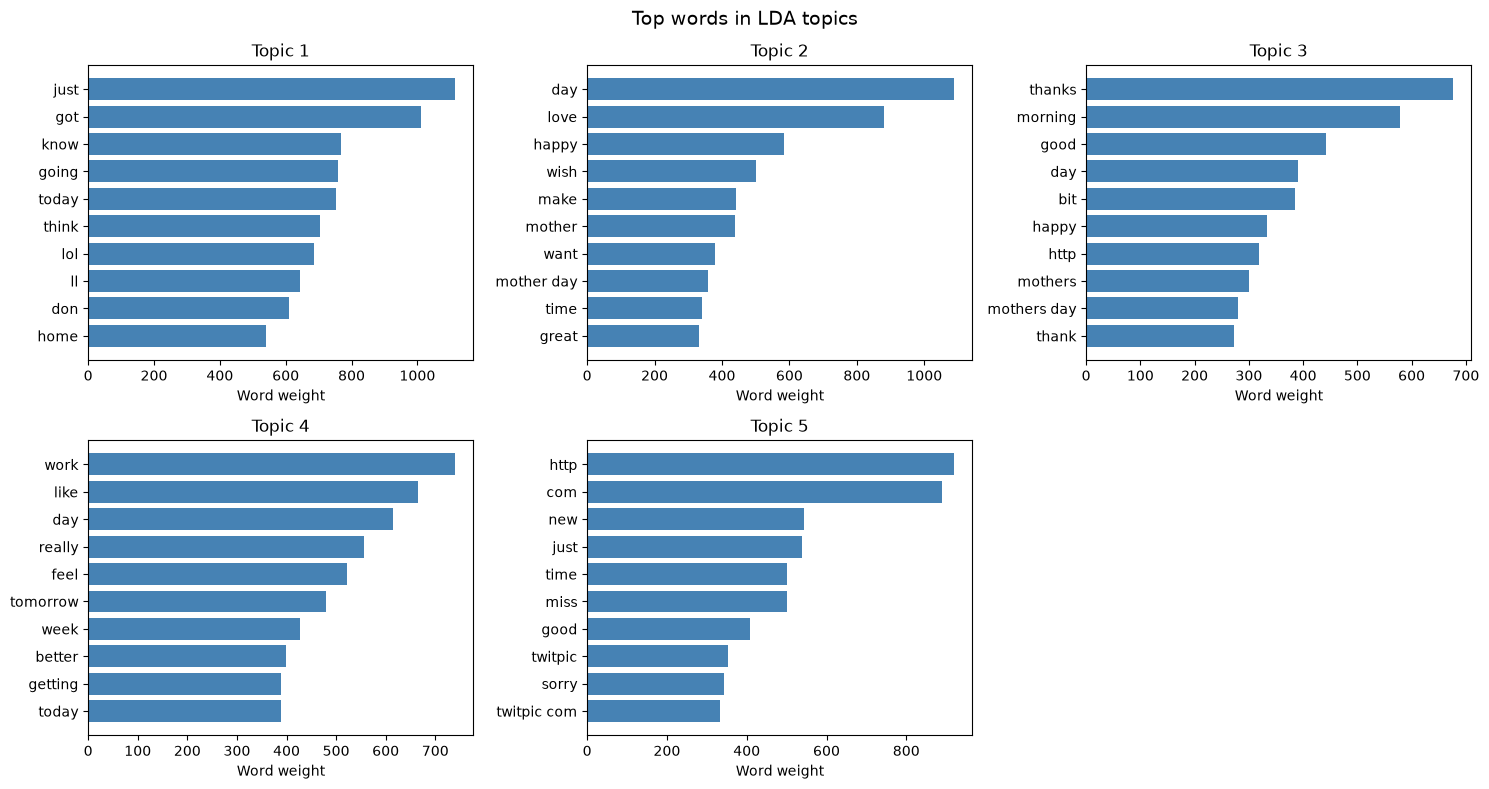

Tweet counts by dominant topic and sentiment:


sentiment,negative,neutral,positive
Topic,,,
1,2227,3467,1871
2,880,1666,2379
3,987,1438,1591
4,1967,2412,1533
5,1720,2134,1208


Sentiment distribution within each topic (%):


sentiment,negative,neutral,positive
Topic,,,
1,29.4,45.8,24.7
2,17.9,33.8,48.3
3,24.6,35.8,39.6
4,33.3,40.8,25.9
5,34.0,42.2,23.9


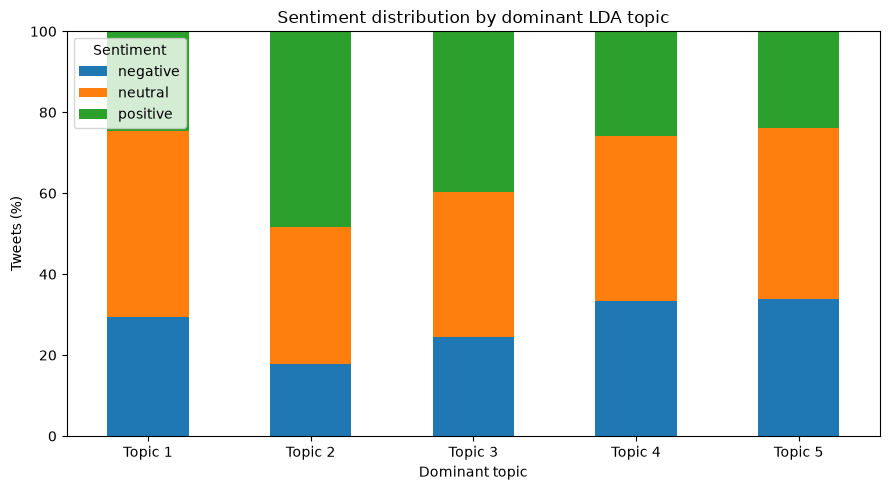

In [ ]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer


lda_data = data.loc[
    data["text"].notna() & data["sentiment"].notna(), ["text", "sentiment"]
].copy()
lda_data["text"] = lda_data["text"].astype(str).str.strip()
lda_data = lda_data.loc[lda_data["text"] != ""].reset_index(drop=True)

vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95,
    max_features=1000,
)
doc_term_matrix = vectorizer.fit_transform(lda_data["text"])

n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch",
    max_iter=10,
)
doc_topic_distribution = lda_model.fit_transform(doc_term_matrix)
lda_data["Topic"] = doc_topic_distribution.argmax(axis=1) + 1

feature_names = vectorizer.get_feature_names_out()
n_top_words = 10
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for topic_id, topic_weights in enumerate(lda_model.components_):
    top_word_indices = topic_weights.argsort()[-n_top_words:][::-1]
    top_words = feature_names[top_word_indices]
    top_weights = topic_weights[top_word_indices]
    axes[topic_id].barh(top_words[::-1], top_weights[::-1], color="steelblue")
    axes[topic_id].set_title(f"Topic {topic_id + 1}")
    axes[topic_id].set_xlabel("Word weight")

axes[-1].axis("off")
fig.suptitle("Top words in LDA topics", fontsize=14)
fig.tight_layout()
plt.show()

sentiment_order = [
    label
    for label in ["negative", "neutral", "positive"]
    if label in lda_data["sentiment"].unique()
]
sentiment_order += sorted(
    set(lda_data["sentiment"].unique()) - set(sentiment_order)
)
topic_sentiment_counts = pd.crosstab(
    lda_data["Topic"], lda_data["sentiment"]
).reindex(columns=sentiment_order, fill_value=0)
topic_sentiment_percent = topic_sentiment_counts.div(
    topic_sentiment_counts.sum(axis=1), axis=0
).mul(100)

print("Tweet counts by dominant topic and sentiment:")
display(topic_sentiment_counts)
print("Sentiment distribution within each topic (%):")
display(topic_sentiment_percent.round(1))

topic_sentiment_percent.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Sentiment distribution by dominant LDA topic")
plt.xlabel("Dominant topic")
plt.ylabel("Tweets (%)")
plt.xticks(
    ticks=range(n_topics),
    labels=[f"Topic {topic_id + 1}" for topic_id in range(n_topics)],
    rotation=0,
)
plt.ylim(0, 100)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()